# Grid-search example

Fit `vsini` and `vmacro` to four synthetic absorption lines (A–D) using a grid of broadened models (`toy_lines.py`).

- True values: `vsini = 100` km/s and `vmacro = 10` km/s. The line centres, strengths and intrinsic widths are known,
  so `n_params = 2`.
- The noise is correlated over a few pixels, as after rebinning or stacking.
- The observed errors are too small, by a factor of 0.8.
- Line D has `vsini = 140` km/s, mimicking a problem line (a blend, a poor model, a normalization error).

We compare the naive fit (observed errors, `n_pix − n_params` degrees of freedom) with `wellfit`.

In [1]:
import sys
sys.path.insert(0, '..')   # or install the package: pip install -e ..
import numpy as np
import matplotlib.pyplot as plt
import wellfit as wf
import toy_lines as tl     # toy broadening model + synthetic data for these examples
%matplotlib inline

## 1. Data

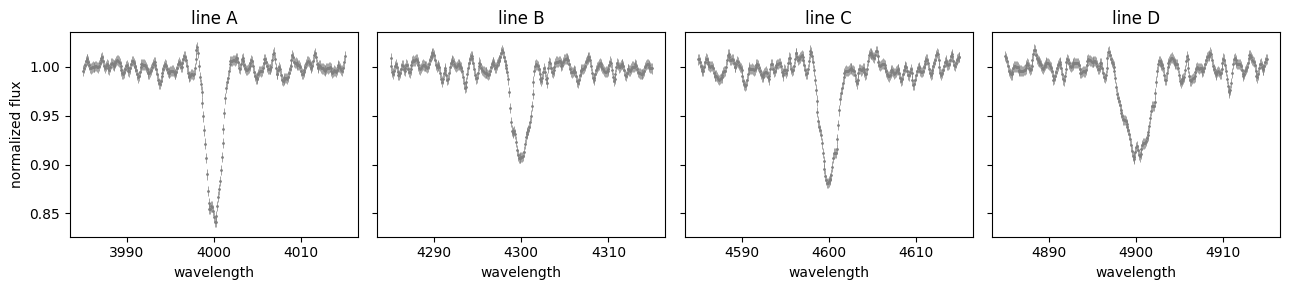

In [2]:
# Select a set of "true" parameters for the synthetic data
TRUTH = dict(vsini=100., vmacro=10., vsini_D=140., snr=150.)

# Generate synthetic data with the above parameters
d = tl.make_data(**TRUTH)
lam_obs, flux_obs, err_obs, groups, names = d['lam'], d['flux'], d['err'], d['groups'], d['names']

# Plot the synthetic data
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for j, ax in enumerate(axs):
    m = groups == j
    ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m], fmt='.', ms=2, color='0.5', lw=0.5)
    ax.set_title(f'line {names[j]}'); ax.set_xlabel('wavelength')
axs[0].set_ylabel('normalized flux'); plt.tight_layout()

## 2. Noise

Both quantities are measured in the line-free continuum next to each line (`d['ref_ranges']`), with a constant
baseline (`deg=0`).

- `measure_error_scale`: the factor that brings the continuum scatter to unit width (expected ≈ 1.25).
- `measure_n_corr`: the number of correlated pixels (expected ≈ 5). Short continuum segments bias it slightly low.

error scale factor = 1.26   (injected 1 / 0.8 = 1.25)


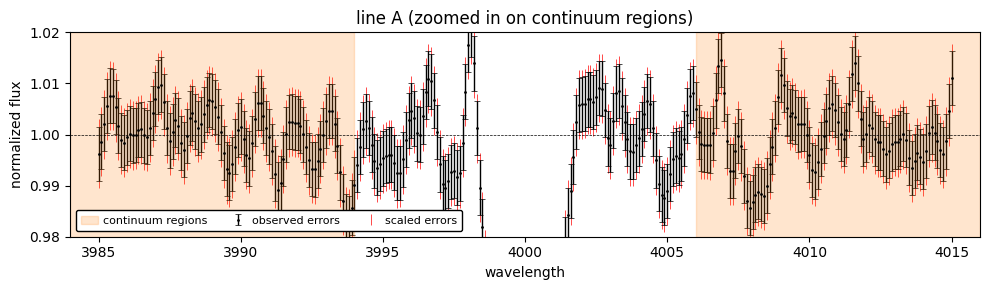

In [3]:
# Measure the error scale factor (i.e., how much the observed errors need to be scaled to match the actual scatter)
err_obs_scaled, factor = wf.measure_error_scale(lam_obs, flux_obs, err_obs, d['ref_ranges'], deg=0)
print(f"error scale factor = {factor:.2f}   (injected 1 / 0.8 = 1.25)")

# Plot the measured error scale factor for one of the lines, zoomed in on continuum regions
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
m = groups == 0
ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m], fmt='.', ms=2, color='k', lw=1, zorder=1, capthick=0.5, capsize=2, label='observed errors')
# Scale the errors by the measured factor to show that the scatter is now consistent with the errors
ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m] * factor, fmt='None', ms=2, color='red', lw=0.5, zorder=0, label='scaled errors')
ax.set_title(f'line {names[0]} (zoomed in on continuum regions)'); ax.set_xlabel('wavelength'); ax.set_ylabel('normalized flux')
for j in range(2):
    ax.axvspan(d['ref_ranges'][j][0], d['ref_ranges'][j][1], color='C1', alpha=0.2, label='continuum regions' if j == 0 else None)
ax.set_xlim(d['ref_ranges'][0][0], d['ref_ranges'][1][1]); plt.tight_layout()
ax.axhline(1, color='k', ls='--', lw=0.5)
ax.set_ylim(0.98, 1.02)
ax.legend(loc='lower left', fontsize=8, frameon=True, 
          framealpha=1, fancybox=True, edgecolor='k', facecolor='w', handlelength=1.5, handletextpad=0.5, borderpad=0.5, ncol=3)
plt.tight_layout()

In [4]:
# Measure the number of correlated pixels and the correlation coefficients
n_corr, rho = wf.measure_n_corr(lam_obs, flux_obs, err_obs, d['ref_ranges'], deg=0)
print(f"n_corr = {n_corr:.2f}   (injected {d['truth']['n_corr']:.2f}); rho_1..4 = {np.round(rho[:4], 2)}")
print(f"{lam_obs.size} pixels -> {lam_obs.size / n_corr:.0f} independent pixels")

n_corr = 4.94   (injected 5.32); rho_1..4 = [0.88 0.62 0.34 0.13]
1204 pixels -> 244 independent pixels


## 3. Residual matrix

`fit_grid` only needs the residuals (model − data) of every grid model, shape `(n_models, n_pix)`, and the line each
pixel belongs to (`groups`).

In [5]:
vsini_axis, vmacro_axis = np.arange(0, 201, 2.), np.arange(0, 61, 2.)
VS, VM = [a.ravel() for a in np.meshgrid(vsini_axis, vmacro_axis, indexing='ij')]   # flattened grid
R = np.stack([tl.model(lam_obs, groups, vs, vm) for vs, vm in zip(VS, VM)]) - flux_obs
print(R.shape, '(n_models, n_pix)')

(3131, 1204) (n_models, n_pix)


## 4. Naive fit vs `wellfit`

| | errors | pixels | systematic floor |
|---|---|---|---|
| naive | `err_obs` | independent | none |
| `wellfit` | `err_obs_scaled` | `χ²_eff = χ² / n_corr` | `sigma_sys`, so that the reduced `χ²_eff` = 1 |

`wellfit` also gives per-line diagnostics and systematic errors from a bootstrap over lines.

In [6]:
params = {'vsini': VS, 'vmacro': VM}
naive = wf.fit_grid(R, err_obs, n_corr=1., n_params=2, params=params, fit_sigma_sys=False)
fit = wf.fit_grid(R, err_obs_scaled, n_corr, n_params=2, groups=groups, params=params, group_names=names)

print(f"naive: chi2 = {naive.chi2[naive.best]:.0f} for n_pix - n_params = {naive.nu:.0f} dof "
      f"(reduced chi2 = {naive.chi2[naive.best] / naive.nu:.1f})")
for k in params:
    v, ep, em, _, _ = naive.results[k]
    print(f"  {k:7s} = {v:5.0f} +{ep:.0f} -{em:.0f}")
print()
print(fit.summary())

naive: chi2 = 2887 for n_pix - n_params = 1202 dof (reduced chi2 = 2.4)
  vsini   =   106 +2 -2
  vmacro  =    22 +2 -2

n_data = 1204, n_corr = 4.94 -> 243.8 independent points, nu = 241.8
sigma_sys = 0.004858; best model 1654: chi2 = 1818.3 (raw), chi2_eff = 241.8
Parameters (value +stat -stat, +sys -sys):
  vsini             106  +4 -4   sys +10 -6
  vmacro             22  +6 -4   sys +6 -10
Groups (chi2_eff / expected, tension, leave-one-out best vsini, vmacro):
  A                0            40.9 /   60.9  tension    6.1  110  28
  B                0            43.3 /   60.9  tension    0.7  106  26
  C                0            56.7 /   60.9  tension    3.0  110  24
  D                0           100.9 /   60.9  tension   18.1  100  14


The naive fit has a reduced χ² ≈ 2.4, yet its errors are only one grid step. `wellfit`:

- counts about 5× fewer independent pixels;
- adds the systematic floor that the misfit requires;
- adds a systematic error from the bootstrap over lines.

Line D has by far the largest tension.

## 5. Confidence regions

The joint 68% (solid) and 95% (dashed) regions, at Δχ² = 2.30 and 6.18. Both fits include line D, which biases them.
The naive region excludes the truth. The `wellfit` region is larger but still biased. Section 6 deals with the bias.

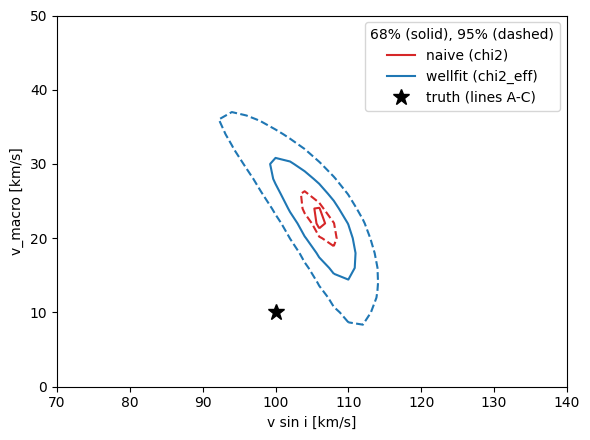

In [7]:
def dchi2_map(c2):
    c2 = c2.reshape(vsini_axis.size, vmacro_axis.size)
    return (c2 - c2.min()).T

fig, ax = plt.subplots(figsize=(6, 4.5))
for c2, col, lab in [(naive.chi2, 'C3', 'naive (chi2)'), (fit.chi2_eff, 'C0', 'wellfit (chi2_eff)')]:
    ax.contour(vsini_axis, vmacro_axis, dchi2_map(c2), levels=[2.30, 6.18], colors=col, linestyles=['-', '--'])
    ax.plot([], [], color=col, label=lab)
ax.plot(TRUTH['vsini'], TRUTH['vmacro'], 'k*', ms=12, label='truth (lines A-C)')
ax.set_xlim(70, 140); ax.set_ylim(0, 50)
ax.set_xlabel('v sin i [km/s]'); ax.set_ylabel('v_macro [km/s]'); ax.legend(title='68% (solid), 95% (dashed)')
plt.tight_layout()

## 6. Tension

The tension of a line is the drop in the other lines' `χ²_eff` when that line is left out and the grid refitted.
Consistent lines sit near 0. Line D stands out, so we refit without it.

n_data = 903, n_corr = 4.94 -> 182.8 independent points, nu = 180.8
sigma_sys = 0.001247; best model 1557: chi2 = 923.9 (raw), chi2_eff = 180.8
Parameters (value +stat -stat, +sys -sys):
  vsini             100  +4 -2   sys +4 -2
  vmacro             14  +2 -8   sys +2 -8
Groups (chi2_eff / expected, tension, leave-one-out best vsini, vmacro):
  A                0            47.9 /   60.9  tension    0.7  102  8
  B                0            61.4 /   60.9  tension    0.3  98  16
  C                0            71.5 /   60.9  tension    0.7  102  12


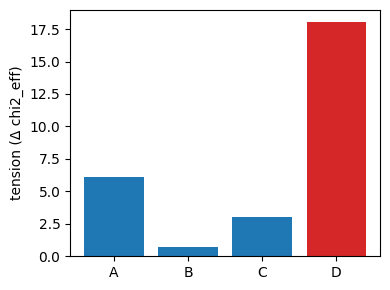

In [8]:
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(names, fit.tension, color=['C0'] * 3 + ['C3'])
ax.set_ylabel('tension (Δ chi2_eff)'); plt.tight_layout()

keep = groups != names.index('D')
fit_noD = wf.fit_grid(R[:, keep], err_obs_scaled[keep], n_corr, n_params=2, groups=groups[keep], params=params,
                      group_names=names[:3])
print(fit_noD.summary())

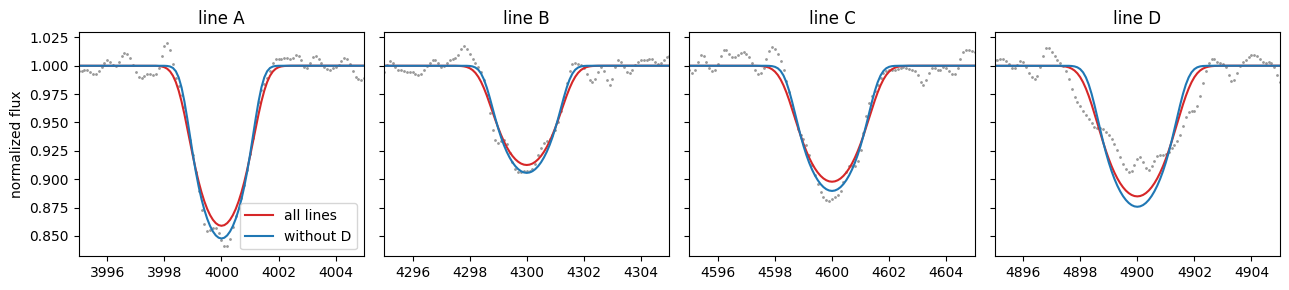

In [9]:
best = lambda f: tl.model(lam_obs, groups, VS[f.best], VM[f.best])
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for j, ax in enumerate(axs):
    m = groups == j
    ax.plot(lam_obs[m], flux_obs[m], '.', ms=2, color='0.6')
    ax.plot(lam_obs[m], best(fit)[m], 'C3', label='all lines')
    ax.plot(lam_obs[m], best(fit_noD)[m], 'C0', label='without D')
    ax.set_title(f'line {names[j]}'); ax.set_xlim(tl.LINES[names[j]][0] - 5, tl.LINES[names[j]][0] + 5)
axs[0].legend(); axs[0].set_ylabel('normalized flux'); plt.tight_layout()

## 7. 2D posterior: lines A–D vs A–C

Shading: the posterior `exp(−χ²_eff/2)`, with 68% and 95% contours. Points: the bootstrap best fits, sized by the
number of replicates.

- **Lines A–D:** the posterior is biased. The bootstrap points scatter far outside the contours, so the sys error
  exceeds the stat error, and `sigma_sys` is large.
- **Lines A–C:** `sigma_sys` drops by about 4×. The contours shrink and contain the truth, and the bootstrap points fall
  inside them (sys ≈ stat).

Tension shows which line to inspect. Remove a line only for a physical reason, not because of its tension alone.

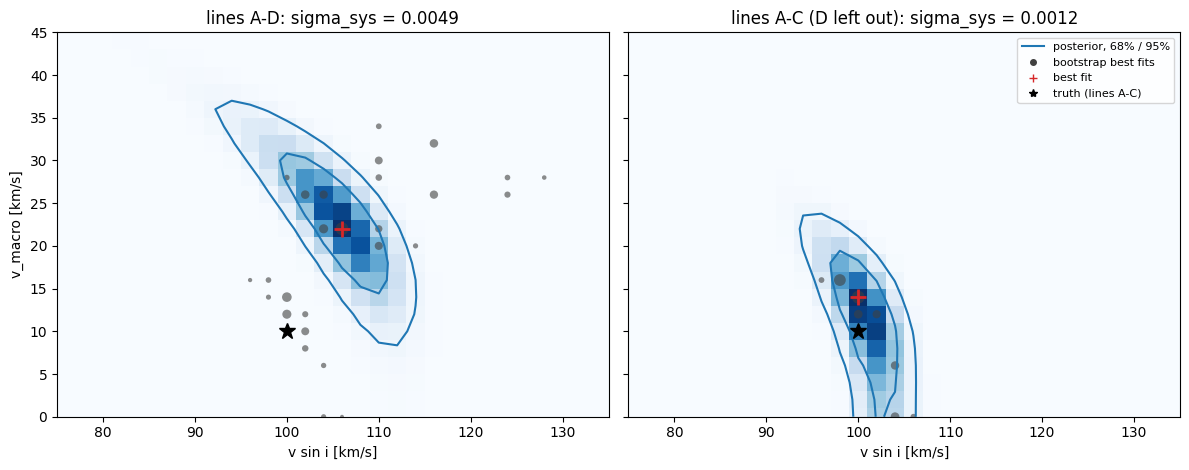

In [10]:
def plot_post2d(ax, d2, x, y, best, boot=None, d2_curv=None, title=''):
    # posterior exp(-Delta chi2_eff / 2) on the (y, x) mesh, its 68% / 95% contours (2 parameters), the curvature
    # ellipses, and the bootstrap best fits (marker size = number of replicates at that point)
    ax.pcolormesh(x, y, np.exp(-0.5 * d2), cmap='Blues', shading='auto')
    ax.contour(x, y, d2, levels=[2.30, 6.18], colors='C0', linestyles='-')
    if d2_curv is not None:
        ax.contour(x, y, d2_curv, levels=[2.30, 6.18], colors='C1', linestyles='--')
    if boot is not None:
        pts, n = np.unique(np.round(boot, 4), axis=0, return_counts=True)
        ax.scatter(*pts.T, s=6 + 80 * n / n.max(), color='0.25', alpha=0.6, lw=0)
    ax.plot(*best, 'C3+', ms=12, mew=2)
    ax.plot(TRUTH['vsini'], TRUTH['vmacro'], 'k*', ms=12)
    ax.set_xlim(x[0], x[-1]); ax.set_ylim(y[0], y[-1])
    ax.set_title(title); ax.set_xlabel('v sin i [km/s]')

def legend2d(ax, ellipse=False):
    items = [('posterior, 68% / 95%', dict(color='C0'))]
    items += [('curvature ellipse', dict(color='C1', ls='--'))] if ellipse else []
    items += [('bootstrap best fits', dict(color='0.25', marker='o', ms=4, ls='')),
              ('best fit', dict(color='C3', marker='+', ls='')), ('truth (lines A-C)', dict(color='k', marker='*', ls=''))]
    for lab, kw in items:
        ax.plot([], [], label=lab, **kw)
    ax.legend(fontsize=8, loc='upper right')

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, f, t in [(axs[0], fit, 'lines A-D'), (axs[1], fit_noD, 'lines A-C (D left out)')]:
    plot_post2d(ax, dchi2_map(f.chi2_eff), vsini_axis, vmacro_axis, (VS[f.best], VM[f.best]),
                boot=np.stack([VS[f.boot_best], VM[f.boot_best]], axis=1),
                title=f"{t}: sigma_sys = {f.sigma_sys:.4f}")
for ax in axs:
    ax.set_xlim(75, 135); ax.set_ylim(0, 45)
axs[0].set_ylabel('v_macro [km/s]'); legend2d(axs[1]); plt.tight_layout()

## Summary

| Problem | `wellfit` |
|---|---|
| wrong error bars | `measure_error_scale` |
| correlated pixels | `measure_n_corr`; `χ²_eff = χ² / n_corr`, `ν = n_pix / n_corr − n_params` |
| imperfect model | `sigma_sys`, so that the reduced `χ²_eff` = 1 |
| inconsistent data | `tension`, leave-one-out fits |
| parameter errors | stat: from the posterior, at least one grid step; sys: from the bootstrap over lines |

For continuous parameters see `optimizer_example.ipynb`; for MCMC see `mcmc_example.ipynb`.